# SegFormer vs SegFormer+MaxSig — Ablation Study (B0 → B5)

This notebook trains and evaluates, for every SegFormer backbone size **B0–B5**:
- the **baseline SegFormer** (no MaxSig gates), and
- **SegFormer+MaxSig** (MaxSigGate inserted after encoder stages `maxsig_stages`).

Each backbone's baseline-vs-MaxSig comparison lives in **its own cell** further down
(one cell trains + evaluates both variants and prints/plots the comparison).

> ⚠️ With `epochs=100` this means **12 full training runs** (6 backbones × 2 variants).
> Lower `config['epochs']` below for a quick smoke test before committing to the full run.

In [5]:
ROOT = '/home/jupyter-r.yazdi/myproject/dti3d/0pycodes/UnetMaxsig/BUSI_WHU/'

config = {
    "lr": 1e-4,
    "batch_size": 8,
    "epochs": 100,
    "maxsig_stages": (1, 2),   # which encoder stages get MaxSigGate when use_maxsig=True
    "maxsig_kernel": 3,
    "gamma_init": 0.0,         # 0 => MaxSig gate is a no-op at init, learns how much to mix in
}

BACKBONES = ["b0", "b1", "b2", "b3", "b4", "b5"]


In [6]:
from time import perf_counter
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd

import os
from glob import glob
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
from torchvision import transforms
import torchvision.transforms.functional as TF
from torchvision.utils import make_grid
from PIL import Image

from torch.optim.lr_scheduler import StepLR
from torch.utils.data import DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2

from transformers import SegformerConfig, SegformerDecodeHead

from scipy.ndimage import binary_erosion, distance_transform_edt, generate_binary_structure

# thop gives us MACs/FLOPs for an arbitrary nn.Module forward pass
try:
    from thop import profile as thop_profile
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "thop", "--quiet"])
    from thop import profile as thop_profile

torch.manual_seed(42)
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("device:", device)


device: cuda:0


## Dataset

In [7]:
#dataset
from torch.utils.data import Dataset
class mydataset(Dataset):
    def __init__(self,images_dir,masks_dir,transforms_img=None):
        self.images_dir=images_dir
        self.masks_dir=masks_dir
        self.transforms_img=transforms_img
        self.mask_names= glob(masks_dir + "*.bmp")

    def __len__(self):
        return len(self.mask_names)

    def __getitem__(self,index):
        mask_name=self.mask_names[index]
        mask=cv2.imread(mask_name,cv2.IMREAD_ANYDEPTH)
        mask = (mask - mask.min()) / (mask.max() - mask.min())#ejbari
        mask= (mask>0).astype(np.float32)
        mask = cv2.resize(mask, (256, 256), interpolation=cv2.INTER_AREA)

        imgn=mask_name.replace('/masks/','/images/').replace('_anno.bmp','.bmp')
              
        image=cv2.imread(imgn,cv2.IMREAD_ANYDEPTH)
        image = (image - image.min()) / (image.max() - image.min()).astype(np.float32)#ejbari
        image = cv2.resize(image, (256, 256), interpolation=cv2.INTER_AREA)

        if self.transforms_img is not None:
            transformed = self.transforms_img(image=image, mask=mask)
            image = transformed["image"]
            mask = transformed["mask"]

        return image, mask

In [8]:
#train dataset

images_dir= ROOT + 'dataset/train/images/'
masks_dir= ROOT + 'dataset/train/masks/'
batch_size=config['batch_size']
shuffle=True

train_transform = A.Compose([
    ToTensorV2()])

train_ds=mydataset(images_dir=images_dir,masks_dir=masks_dir,transforms_img=train_transform)
print("number of loaded training images: ",train_ds.__len__())

train_dataset = DataLoader(train_ds,batch_size=batch_size,shuffle=shuffle)
print("loaded", len(train_dataset), "training batches.")


number of loaded training images:  555
loaded 70 training batches.


In [9]:
#val dataset

images_dir= ROOT + 'dataset/val/images/'
masks_dir= ROOT + 'dataset/val/masks/'
batch_size=config['batch_size']
shuffle=True

val_transform = A.Compose([
    ToTensorV2()])

val_ds=mydataset(images_dir=images_dir,masks_dir=masks_dir,transforms_img=val_transform)
print("number of loaded val images: ",val_ds.__len__())

val_dataset = DataLoader(val_ds,batch_size=batch_size,shuffle=shuffle)
print("loaded", len(val_dataset), "validation batches.")


number of loaded val images:  186
loaded 24 validation batches.


In [10]:
#test dataset

images_dir= ROOT + 'dataset/test/images/'
masks_dir= ROOT + 'dataset/test/masks/'
batch_size=config['batch_size']
shuffle=True

test_transform = A.Compose([
    ToTensorV2()])

test_ds=mydataset(images_dir=images_dir,masks_dir=masks_dir,transforms_img=test_transform)
print("number of loaded test images: ",test_ds.__len__())

test_dataset = DataLoader(test_ds,batch_size=batch_size,shuffle=shuffle)
print("loaded", len(test_dataset), "test batches.")


number of loaded test images:  186
loaded 24 test batches.


## Model — MaxSig layer/gate + from-scratch SegFormer (MiT encoder + decode head)

In [11]:
# ============================================================
# MaxSigLayerNormalized — unchanged.
# ============================================================
class MaxSigLayerNormalized(nn.Module):
    """
    Args:
        ch_in (int): input channels
        ch_out (int): output channels
        kernel_size (int): odd recommended
        stride (int): keep 1 to preserve H,W
        use_sigmoid_input (bool): apply sigmoid(x) before unfolding
    """
    def __init__(
        self,
        ch_in: int,
        ch_out: int,
        kernel_size: int,
        stride: int = 1,
        use_sigmoid_input: bool = True,
    ):
        super().__init__()
        assert kernel_size >= 1
        self.ch_in = ch_in
        self.ch_out = ch_out
        self.kernel_size = kernel_size
        self.stride = stride
        self.use_sigmoid_input = use_sigmoid_input

        self.padding = (kernel_size - 1) // 2
        self.kernel_area = kernel_size ** 2
        self.center_index = self.kernel_area // 2

        # learnable patch weights / bias (shared)
        self.weight = nn.Parameter(torch.rand(1, 1, self.kernel_area, 1, 1))
        self.bias   = nn.Parameter(torch.zeros(1, 1, self.kernel_area, 1, 1))

        # learnable scalars
        self.weight_center = nn.Parameter(torch.tensor(1.0))
        self.weight_median = nn.Parameter(torch.tensor(1.0))

        # proper projection
        self.proj = nn.Conv2d(ch_in, ch_out, kernel_size=1, bias=False)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B, C_in, H, W = x.shape
        assert C_in == self.ch_in, f"Expected {self.ch_in} channels, got {C_in}"

        x_in = torch.sigmoid(x) if self.use_sigmoid_input else x

        x_unfold = F.unfold(
            x_in,
            kernel_size=self.kernel_size,
            padding=self.padding,
            stride=self.stride,
        )  # (B, C_in*K*K, L)

        _, CK2, L = x_unfold.shape
        assert CK2 == C_in * self.kernel_area

        out_h = (H + 2 * self.padding - self.kernel_size) // self.stride + 1
        out_w = (W + 2 * self.padding - self.kernel_size) // self.stride + 1

        x_unfold = x_unfold.view(B, C_in, self.kernel_area, out_h, out_w)

        w = torch.sigmoid(self.weight)  # (1,1,K*K,1,1)
        b = torch.sigmoid(self.bias)    # (1,1,K*K,1,1)

        D = torch.maximum(w, x_unfold) + b  # (B,C,K*K,out_h,out_w)

        mean_stat = torch.mean(D, dim=2)         # (B,C,out_h,out_w)
        median_stat, _ = torch.median(D, dim=2)  # (B,C,out_h,out_w)

        center_values = x_unfold[:, :, self.center_index, :, :]  # (B,C,out_h,out_w)

        out = (
            self.weight_center * center_values
            + self.weight_median * median_stat
            - mean_stat
        )  # (B,C_in,out_h,out_w)

        out = self.proj(out)  # (B,C_out,out_h,out_w)
        return out


# ============================================================
# MaxSigGate — the Segformer analogue of your UNet's
# DownBlockWithMaxSig. Applied as a gated residual right after a
# stage's (B,C,H,W) output:
#     x = x + gamma * post(maxsig(x))
# gamma starts at 0 => architecturally identical to a baseline
# (MaxSig-free) SegFormer at initialization, and the network learns
# how much MaxSig signal to mix in during training.
# ============================================================
class MaxSigGate(nn.Module):
    def __init__(self, channels: int, kernel_size: int = 3, gamma_init: float = 0.0,
                 use_sigmoid_input: bool = True):
        super().__init__()
        self.maxsig = MaxSigLayerNormalized(
            ch_in=channels, ch_out=channels, kernel_size=kernel_size,
            stride=1, use_sigmoid_input=use_sigmoid_input,
        )
        # light post-processing helps stabilize, same as the UNet version
        self.post = nn.Sequential(
            nn.BatchNorm2d(channels),
            nn.LeakyReLU(0.1, inplace=True),
        )
        self.gamma = nn.Parameter(torch.tensor(gamma_init))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        m = self.maxsig(x)
        m = self.post(m)
        return x + self.gamma * m


# ============================================================
# Standalone Mix Transformer (MiT) encoder — SegFormer's encoder,
# reimplemented here from the paper instead of pulled out of
# transformers.SegformerModel (whose internal module layout has
# changed across transformers versions). SegformerConfig and
# SegformerDecodeHead are the stable, public parts of the API, so we
# only depend on those and rebuild the encoder ourselves. Training is
# from scratch anyway, so there's no pretrained encoder weight layout
# we need to match.
# ============================================================
class OverlapPatchEmbed(nn.Module):
    """Conv-based patch embedding with overlapping patches (stride < kernel_size)."""
    def __init__(self, in_ch, embed_dim, patch_size, stride):
        super().__init__()
        self.proj = nn.Conv2d(in_ch, embed_dim, kernel_size=patch_size,
                               stride=stride, padding=patch_size // 2)
        self.norm = nn.LayerNorm(embed_dim)

    def forward(self, x):
        x = self.proj(x)
        _, _, H, W = x.shape
        x = x.flatten(2).transpose(1, 2)   # (B, N, C)
        x = self.norm(x)
        return x, H, W


class EfficientSelfAttention(nn.Module):
    """Multi-head self-attention with spatial-reduction on K/V (SegFormer's SRA)."""
    def __init__(self, dim, num_heads, sr_ratio, attn_drop=0.0, proj_drop=0.0):
        super().__init__()
        self.num_heads = num_heads
        self.head_dim = dim // num_heads
        self.scale = self.head_dim ** -0.5
        self.q = nn.Linear(dim, dim, bias=True)
        self.kv = nn.Linear(dim, dim * 2, bias=True)
        self.proj = nn.Linear(dim, dim)
        self.attn_drop = nn.Dropout(attn_drop)
        self.proj_drop = nn.Dropout(proj_drop)
        self.sr_ratio = sr_ratio
        if sr_ratio > 1:
            self.sr = nn.Conv2d(dim, dim, kernel_size=sr_ratio, stride=sr_ratio)
            self.norm = nn.LayerNorm(dim)

    def forward(self, x, H, W):
        B, N, C = x.shape
        q = self.q(x).reshape(B, N, self.num_heads, self.head_dim).permute(0, 2, 1, 3)

        if self.sr_ratio > 1:
            x_ = x.permute(0, 2, 1).reshape(B, C, H, W)
            x_ = self.sr(x_).reshape(B, C, -1).permute(0, 2, 1)
            x_ = self.norm(x_)
            kv = self.kv(x_)
        else:
            kv = self.kv(x)
        kv = kv.reshape(B, -1, 2, self.num_heads, self.head_dim).permute(2, 0, 3, 1, 4)
        k, v = kv[0], kv[1]

        attn = (q @ k.transpose(-2, -1)) * self.scale
        attn = attn.softmax(dim=-1)
        attn = self.attn_drop(attn)

        out = (attn @ v).transpose(1, 2).reshape(B, N, C)
        out = self.proj(out)
        out = self.proj_drop(out)
        return out


class DWConv(nn.Module):
    """Depthwise 3x3 conv used inside Mix-FFN to inject local/positional info."""
    def __init__(self, dim):
        super().__init__()
        self.dwconv = nn.Conv2d(dim, dim, kernel_size=3, padding=1, groups=dim)

    def forward(self, x, H, W):
        B, N, C = x.shape
        x = x.transpose(1, 2).reshape(B, C, H, W)
        x = self.dwconv(x)
        x = x.flatten(2).transpose(1, 2)
        return x


class MixFFN(nn.Module):
    """SegFormer's Mix-FFN: Linear -> DWConv -> GELU -> Linear."""
    def __init__(self, dim, hidden_dim, drop=0.0):
        super().__init__()
        self.fc1 = nn.Linear(dim, hidden_dim)
        self.dwconv = DWConv(hidden_dim)
        self.act = nn.GELU()
        self.fc2 = nn.Linear(hidden_dim, dim)
        self.drop = nn.Dropout(drop)

    def forward(self, x, H, W):
        x = self.fc1(x)
        x = self.dwconv(x, H, W)
        x = self.act(x)
        x = self.drop(x)
        x = self.fc2(x)
        x = self.drop(x)
        return x


class DropPath(nn.Module):
    """Stochastic depth, applied per-sample."""
    def __init__(self, drop_prob=0.0):
        super().__init__()
        self.drop_prob = drop_prob

    def forward(self, x):
        if self.drop_prob == 0.0 or not self.training:
            return x
        keep_prob = 1 - self.drop_prob
        shape = (x.shape[0],) + (1,) * (x.ndim - 1)
        random_tensor = keep_prob + torch.rand(shape, dtype=x.dtype, device=x.device)
        random_tensor.floor_()
        return x.div(keep_prob) * random_tensor


class MixTransformerBlock(nn.Module):
    def __init__(self, dim, num_heads, mlp_ratio, sr_ratio, drop=0.0, attn_drop=0.0,
                 drop_path=0.0, layer_norm_eps=1e-6):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim, eps=layer_norm_eps)
        self.attn = EfficientSelfAttention(dim, num_heads, sr_ratio, attn_drop, drop)
        self.drop_path = DropPath(drop_path)
        self.norm2 = nn.LayerNorm(dim, eps=layer_norm_eps)
        self.mlp = MixFFN(dim, dim * mlp_ratio, drop)

    def forward(self, x, H, W):
        x = x + self.drop_path(self.attn(self.norm1(x), H, W))
        x = x + self.drop_path(self.mlp(self.norm2(x), H, W))
        return x


class MixVisionTransformerStage(nn.Module):
    """One encoder stage: overlap patch embed -> transformer blocks -> layernorm
    -> reshape back to (B, C, H, W)."""
    def __init__(self, in_ch, embed_dim, patch_size, stride, depth, num_heads, mlp_ratio,
                 sr_ratio, drop=0.0, attn_drop=0.0, drop_path_rates=None, layer_norm_eps=1e-6):
        super().__init__()
        self.patch_embed = OverlapPatchEmbed(in_ch, embed_dim, patch_size, stride)
        drop_path_rates = drop_path_rates or [0.0] * depth
        self.blocks = nn.ModuleList([
            MixTransformerBlock(embed_dim, num_heads, mlp_ratio, sr_ratio, drop, attn_drop,
                                 drop_path_rates[j], layer_norm_eps)
            for j in range(depth)
        ])
        self.norm = nn.LayerNorm(embed_dim, eps=layer_norm_eps)

    def forward(self, x):
        x, H, W = self.patch_embed(x)
        for blk in self.blocks:
            x = blk(x, H, W)
        x = self.norm(x)
        B, N, C = x.shape
        x = x.transpose(1, 2).reshape(B, C, H, W)
        return x


class MixVisionTransformerEncoder(nn.Module):
    """Full 4-stage Mix Transformer encoder, built entirely from a SegformerConfig."""
    def __init__(self, config: SegformerConfig):
        super().__init__()
        depths = config.depths
        total_depth = sum(depths)
        dpr = [config.drop_path_rate * i / max(total_depth - 1, 1) for i in range(total_depth)]

        self.stages = nn.ModuleList()
        cur = 0
        in_ch = config.num_channels
        for i in range(config.num_encoder_blocks):
            stage_dpr = dpr[cur:cur + depths[i]]
            self.stages.append(MixVisionTransformerStage(
                in_ch=in_ch,
                embed_dim=config.hidden_sizes[i],
                patch_size=config.patch_sizes[i],
                stride=config.strides[i],
                depth=depths[i],
                num_heads=config.num_attention_heads[i],
                mlp_ratio=config.mlp_ratios[i],
                sr_ratio=config.sr_ratios[i],
                drop=config.hidden_dropout_prob,
                attn_drop=config.attention_probs_dropout_prob,
                drop_path_rates=stage_dpr,
                layer_norm_eps=config.layer_norm_eps,
            ))
            cur += depths[i]
            in_ch = config.hidden_sizes[i]

    def forward(self, x):
        hidden_states = []
        for stage in self.stages:
            x = stage(x)
            hidden_states.append(x)
        return hidden_states


# ============================================================
# SegFormer encoder + decode head, trained from scratch, with
# MaxSigGate optionally applied after selected encoder stages.
# Pass maxsig_stages=() to get the plain baseline SegFormer.
# ============================================================
class SegFormerMaxSig(nn.Module):
    def __init__(
        self,
        out_size=(256, 256),
        variant="b0",
        maxsig_stages=(1, 2),     # () => baseline SegFormer, no MaxSig gates at all
        maxsig_kernel=3,
        gamma_init=0.0,
        use_sigmoid_input=True,
    ):
        super().__init__()

        # architecture presets from the SegFormer paper (encoder only differs
        # in depths / hidden_sizes; decoder head size also scales for b4/b5)
        variants = {
            "b0": dict(depths=[2, 2, 2, 2],  hidden_sizes=[32, 64, 160, 256],  decoder_hidden_size=256),
            "b1": dict(depths=[2, 2, 2, 2],  hidden_sizes=[64, 128, 320, 512], decoder_hidden_size=256),
            "b2": dict(depths=[3, 4, 6, 3],  hidden_sizes=[64, 128, 320, 512], decoder_hidden_size=768),
            "b3": dict(depths=[3, 4, 18, 3], hidden_sizes=[64, 128, 320, 512], decoder_hidden_size=768),
            "b4": dict(depths=[3, 8, 27, 3], hidden_sizes=[64, 128, 320, 512], decoder_hidden_size=768),
            "b5": dict(depths=[3, 6, 40, 3], hidden_sizes=[64, 128, 320, 512], decoder_hidden_size=768),
        }
        preset = variants[variant]

        seg_config = SegformerConfig(
            num_channels=1,
            num_labels=1,
            depths=preset["depths"],
            hidden_sizes=preset["hidden_sizes"],
            decoder_hidden_size=preset["decoder_hidden_size"],
        )

        self.encoder = MixVisionTransformerEncoder(seg_config)   # encoder only (random init)
        self.decode_head = SegformerDecodeHead(seg_config)
        self.out_size = out_size

        maxsig_stages = set(maxsig_stages)
        self.maxsig_gates = nn.ModuleDict()
        for i in range(seg_config.num_encoder_blocks):
            if i in maxsig_stages:
                self.maxsig_gates[str(i)] = MaxSigGate(
                    channels=seg_config.hidden_sizes[i],
                    kernel_size=maxsig_kernel,
                    gamma_init=gamma_init,
                    use_sigmoid_input=use_sigmoid_input,
                )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        hidden_states = x
        encoder_hidden_states = []
        for i, stage in enumerate(self.encoder.stages):
            hidden_states = stage(hidden_states)                  # (B, C_i, H_i, W_i)
            if str(i) in self.maxsig_gates:
                hidden_states = self.maxsig_gates[str(i)](hidden_states)
            encoder_hidden_states.append(hidden_states)

        logits = self.decode_head(tuple(encoder_hidden_states))   # [B, 1, H/4, W/4]
        logits = F.interpolate(logits, size=self.out_size, mode="bilinear", align_corners=False)
        return logits


## Metric helpers — IoU, HD95, FLOPs, per-image latency

- **IoU** is derived from the same intersection/union accumulators already used for Dice
  (no extra cost).
- **HD95** (95th-percentile Hausdorff Distance, in pixels) is computed per-image from
  binary mask boundaries via `scipy.ndimage` distance transforms, then averaged over the
  test set. Images where the prediction or the ground truth is empty (no foreground
  pixels) have an undefined boundary distance and are skipped; the skip count is reported.
- **GFLOPs** and **parameter count** are measured once per model via `thop.profile` on a
  single dummy `(1,1,256,256)` input.
- **Per-image inference latency** is measured with CUDA-synchronized wall-clock timing
  over a batch-size-1 forward pass, after a warm-up period.

In [12]:
def compute_hd95(pred_mask: np.ndarray, gt_mask: np.ndarray):
    """95th-percentile symmetric boundary distance (pixels) between two 2D binary masks.
    Returns np.nan if either mask has no foreground pixels (boundary undefined)."""
    pred_mask = pred_mask.astype(bool)
    gt_mask = gt_mask.astype(bool)
    if not pred_mask.any() or not gt_mask.any():
        return np.nan

    conn = generate_binary_structure(pred_mask.ndim, 1)
    pred_border = pred_mask ^ binary_erosion(pred_mask, conn)
    gt_border = gt_mask ^ binary_erosion(gt_mask, conn)

    dt_gt = distance_transform_edt(~gt_border)
    dt_pred = distance_transform_edt(~pred_border)

    sds = np.concatenate([dt_gt[pred_border], dt_pred[gt_border]])
    if sds.size == 0:
        return np.nan
    return float(np.percentile(sds, 95))


def count_flops_params(model, device, input_size=(1, 1, 256, 256)):
    """GFLOPs (~2x MACs) and parameter count for one forward pass, via thop."""
    model.eval()
    dummy = torch.randn(input_size, device=device)
    macs, params = thop_profile(model, inputs=(dummy,), verbose=False)
    gflops = 2 * macs / 1e9
    return gflops, int(params)


def measure_latency(model, device, input_size=(1, 1, 256, 256), n_warmup=10, n_runs=50):
    """Mean/std per-image inference latency (ms), batch size 1, CUDA-synchronized."""
    model.eval()
    dummy = torch.randn(input_size, device=device)
    with torch.no_grad():
        for _ in range(n_warmup):
            _ = model(dummy)
        if device.type == "cuda":
            torch.cuda.synchronize()

        times_ms = []
        for _ in range(n_runs):
            if device.type == "cuda":
                torch.cuda.synchronize()
            t0 = perf_counter()
            _ = model(dummy)
            if device.type == "cuda":
                torch.cuda.synchronize()
            t1 = perf_counter()
            times_ms.append((t1 - t0) * 1000.0)
    return float(np.mean(times_ms)), float(np.std(times_ms))


## Reusable train/eval + comparison-report helpers

`train_and_evaluate(variant, use_maxsig, ...)` trains one model (baseline when
`use_maxsig=False`, i.e. `maxsig_stages=()`; SegFormer+MaxSig when `use_maxsig=True`,
i.e. `maxsig_stages=config['maxsig_stages']`), saves its own best checkpoint, and
reports test-set Dice. `compare_and_report(...)` prints a side-by-side table and
loss/Dice curves for one backbone's baseline-vs-MaxSig pair.

In [13]:
def train_and_evaluate(variant, use_maxsig, config, train_dataset, val_dataset, test_dataset,
                        device, verbose=True):
    torch.manual_seed(42)
    tag = f"segformer_{variant}{'_maxsig' if use_maxsig else '_baseline'}"
    maxsig_stages = config['maxsig_stages'] if use_maxsig else tuple()

    model = SegFormerMaxSig(
        variant=variant,
        maxsig_stages=maxsig_stages,
        maxsig_kernel=config['maxsig_kernel'],
        gamma_init=config['gamma_init'],
    ).to(device)

    total_params = sum(p.numel() for p in model.parameters())
    if verbose:
        print(f"\n{'='*70}\n{tag}  (maxsig_stages={maxsig_stages})\nTotal parameters: {total_params:,}\n{'='*70}")

    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.AdamW(model.parameters(), lr=config['lr'])
    scheduler = StepLR(optimizer, step_size=100, gamma=0.83)
    scaler = torch.amp.GradScaler('cuda')

    eps = 1e-7
    best_valid_dice = 0
    best_epoch = 0
    train_loss_plot, val_loss_plot, val_dice_plot, val_iou_plot = [], [], [], []
    ckpt_path = f'best-model-{tag}.pt'

    for epoch in range(config['epochs']):
        t_start = perf_counter()

        # ---- train ----
        running_loss = 0.0
        model.train()
        for inputs, mask in train_dataset:
            optimizer.zero_grad()
            with torch.autocast(device_type="cuda"):
                outputs = model(inputs.to(device))
                labels = mask.to(device).unsqueeze(1)
                loss = criterion(outputs, labels)
            running_loss += loss.item()
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        ep_train_loss = running_loss / len(train_dataset)
        train_loss_plot.append(ep_train_loss)
        scheduler.step()

        # ---- validate ----
        dice_score = 0
        iou_score = 0
        val_loss = 0.0
        with torch.no_grad():
            model.eval()
            for inputs, mask in val_dataset:
                inputs = inputs.to(device)
                preds = model(inputs)
                labels = mask.to(device).unsqueeze(1)
                loss = criterion(preds, labels)
                val_loss += loss.item()

                pred_sig = torch.sigmoid(preds)
                preds_bin = (pred_sig > 0.5).float()
                intersection = (preds_bin * labels).sum()
                union = (preds_bin + labels).sum()          # = |pred| + |gt|
                dice_score += (2 * intersection / union)
                iou_score += intersection / (union - intersection + eps)  # |pred∪gt| = union - intersection

        ep_val_loss = val_loss / len(val_dataset)
        val_loss_plot.append(ep_val_loss)
        epoch_dc = float(dice_score / len(val_dataset))
        val_dice_plot.append(epoch_dc)
        epoch_iou = float(iou_score / len(val_dataset))
        val_iou_plot.append(epoch_iou)

        if best_valid_dice < epoch_dc:
            best_valid_dice = epoch_dc
            best_epoch = epoch
            torch.save(model.state_dict(), ckpt_path)

        if verbose:
            print(f"[{tag}] epoch {epoch+1}/{config['epochs']}  "
                  f"train_loss={ep_train_loss:.4f}  val_loss={ep_val_loss:.4f}  "
                  f"val_dice={epoch_dc:.4f}  best_dice={best_valid_dice:.4f}@{best_epoch+1}  "
                  f"({perf_counter()-t_start:.1f}s)")

    # ---- reload best checkpoint, evaluate on held-out test set ----
    model.load_state_dict(torch.load(ckpt_path))
    test_dice_score = 0
    test_iou_score = 0
    hd95_values = []
    hd95_skipped = 0
    with torch.no_grad():
        model.eval()
        for inputs, mask in test_dataset:
            inputs = inputs.to(device)
            preds = model(inputs)
            labels = mask.to(device).unsqueeze(1)
            pred_sig = torch.sigmoid(preds)
            preds_bin = (pred_sig > 0.5).float()
            intersection = (preds_bin * labels).sum()
            union = (preds_bin + labels).sum()
            test_dice_score += (2 * intersection / union)
            test_iou_score += intersection / (union - intersection + eps)

            # per-image HD95 (needs individual 2D masks, not batch-level sums)
            preds_np = preds_bin.squeeze(1).cpu().numpy()   # (B, H, W)
            labels_np = labels.squeeze(1).cpu().numpy()     # (B, H, W)
            for b in range(preds_np.shape[0]):
                hd = compute_hd95(preds_np[b], labels_np[b])
                if np.isnan(hd):
                    hd95_skipped += 1
                else:
                    hd95_values.append(hd)

    test_dice = float(test_dice_score / len(test_dataset))
    test_iou = float(test_iou_score / len(test_dataset))
    test_hd95 = float(np.mean(hd95_values)) if hd95_values else float("nan")

    # ---- efficiency metrics: GFLOPs / params (already have total_params) / latency ----
    gflops, thop_params = count_flops_params(model, device)
    latency_mean_ms, latency_std_ms = measure_latency(model, device)

    if verbose:
        print(f"[{tag}] TEST Dice={test_dice:.4f}  IoU={test_iou:.4f}  "
              f"HD95={test_hd95:.2f}px (skipped {hd95_skipped} empty-mask cases)")
        print(f"[{tag}] GFLOPs={gflops:.2f}  Params={total_params:,}  "
              f"Latency={latency_mean_ms:.2f}±{latency_std_ms:.2f} ms/image")

    return {
        'tag': tag,
        'variant': variant,
        'use_maxsig': use_maxsig,
        'total_params': total_params,
        'best_valid_dice': best_valid_dice,
        'best_epoch': best_epoch + 1,
        'test_dice': test_dice,
        'test_iou': test_iou,
        'test_hd95': test_hd95,
        'hd95_skipped': hd95_skipped,
        'gflops': gflops,
        'latency_ms_mean': latency_mean_ms,
        'latency_ms_std': latency_std_ms,
        'train_loss_plot': train_loss_plot,
        'val_loss_plot': val_loss_plot,
        'val_dice_plot': val_dice_plot,
        'val_iou_plot': val_iou_plot,
    }


def compare_and_report(variant, res_baseline, res_maxsig):
    print(f"\n{'#'*70}\n# SegFormer-{variant.upper()}: Baseline vs +MaxSig\n{'#'*70}")
    header = (f"{'Model':<28}{'Params':>12}{'GFLOPs':>9}{'Latency(ms)':>13}"
              f"{'Val Dice':>10}{'Test Dice':>11}{'Test IoU':>10}{'HD95(px)':>10}")
    print(header)
    print('-' * len(header))
    for res in (res_baseline, res_maxsig):
        name = f"SegFormer-{variant}" + ("+MaxSig" if res['use_maxsig'] else " (baseline)")
        print(f"{name:<28}{res['total_params']:>12,}{res['gflops']:>9.2f}"
              f"{res['latency_ms_mean']:>9.2f}±{res['latency_ms_std']:<4.2f}"
              f"{res['best_valid_dice']:>10.4f}{res['test_dice']:>11.4f}"
              f"{res['test_iou']:>10.4f}{res['test_hd95']:>10.2f}")

    d_dice = res_maxsig['test_dice'] - res_baseline['test_dice']
    d_iou = res_maxsig['test_iou'] - res_baseline['test_iou']
    d_hd95 = res_maxsig['test_hd95'] - res_baseline['test_hd95']
    d_params = res_maxsig['total_params'] - res_baseline['total_params']
    d_gflops = res_maxsig['gflops'] - res_baseline['gflops']
    d_latency = res_maxsig['latency_ms_mean'] - res_baseline['latency_ms_mean']
    print(f"\nDelta (MaxSig - baseline): "
          f"Dice={d_dice:+.4f}  IoU={d_iou:+.4f}  HD95={d_hd95:+.2f}px (lower is better)  "
          f"Params={d_params:+,}  GFLOPs={d_gflops:+.2f}  Latency={d_latency:+.2f}ms")

    fig, axes = plt.subplots(1, 4, figsize=(20, 4))
    axes[0].plot(res_baseline['train_loss_plot'], label='baseline')
    axes[0].plot(res_maxsig['train_loss_plot'], label='+maxsig')
    axes[0].set_title(f'{variant}: Train Loss'); axes[0].legend()
    axes[1].plot(res_baseline['val_loss_plot'], label='baseline')
    axes[1].plot(res_maxsig['val_loss_plot'], label='+maxsig')
    axes[1].set_title(f'{variant}: Val Loss'); axes[1].legend()
    axes[2].plot(res_baseline['val_dice_plot'], label='baseline')
    axes[2].plot(res_maxsig['val_dice_plot'], label='+maxsig')
    axes[2].set_title(f'{variant}: Val Dice'); axes[2].legend()
    axes[3].plot(res_baseline['val_iou_plot'], label='baseline')
    axes[3].plot(res_maxsig['val_iou_plot'], label='+maxsig')
    axes[3].set_title(f'{variant}: Val IoU'); axes[3].legend()
    plt.tight_layout()
    plt.show()


all_results = {}  # variant -> (res_baseline, res_maxsig), filled in by the cells below


## SegFormer-B0: baseline vs +MaxSig


segformer_b0_baseline  (maxsig_stages=())
Total parameters: 3,711,265
[segformer_b0_baseline] epoch 1/100  train_loss=0.4858  val_loss=0.3512  val_dice=0.3978  best_dice=0.3978@1  (63.8s)
[segformer_b0_baseline] epoch 2/100  train_loss=0.2745  val_loss=0.2545  val_dice=0.5457  best_dice=0.5457@2  (12.7s)
[segformer_b0_baseline] epoch 3/100  train_loss=0.2057  val_loss=0.1740  val_dice=0.5568  best_dice=0.5568@3  (13.9s)
[segformer_b0_baseline] epoch 4/100  train_loss=0.1686  val_loss=0.1717  val_dice=0.6594  best_dice=0.6594@4  (12.3s)
[segformer_b0_baseline] epoch 5/100  train_loss=0.1483  val_loss=0.1768  val_dice=0.6302  best_dice=0.6594@4  (12.5s)
[segformer_b0_baseline] epoch 6/100  train_loss=0.1310  val_loss=0.1322  val_dice=0.6701  best_dice=0.6701@6  (13.1s)
[segformer_b0_baseline] epoch 7/100  train_loss=0.1205  val_loss=0.1237  val_dice=0.6367  best_dice=0.6701@6  (11.8s)
[segformer_b0_baseline] epoch 8/100  train_loss=0.1104  val_loss=0.1183  val_dice=0.6886  best_dice=0.6

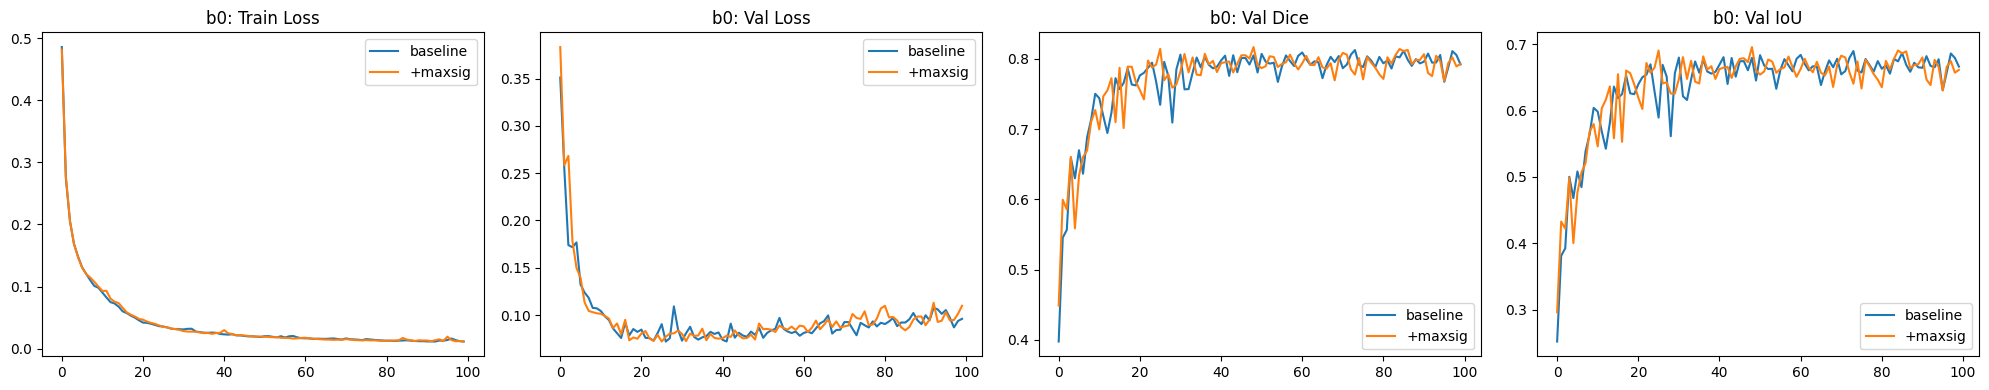

In [14]:
res_b0_baseline = train_and_evaluate(
    "b0", use_maxsig=False, config=config,
    train_dataset=train_dataset, val_dataset=val_dataset, test_dataset=test_dataset,
    device=device,
)

res_b0_maxsig = train_and_evaluate(
    "b0", use_maxsig=True, config=config,
    train_dataset=train_dataset, val_dataset=val_dataset, test_dataset=test_dataset,
    device=device,
)

all_results["b0"] = (res_b0_baseline, res_b0_maxsig)
compare_and_report("b0", res_b0_baseline, res_b0_maxsig)


## SegFormer-B1: baseline vs +MaxSig


segformer_b1_baseline  (maxsig_stages=())
Total parameters: 13,671,233
[segformer_b1_baseline] epoch 1/100  train_loss=0.4588  val_loss=0.2674  val_dice=0.4001  best_dice=0.4001@1  (15.8s)
[segformer_b1_baseline] epoch 2/100  train_loss=0.2567  val_loss=0.2356  val_dice=0.6186  best_dice=0.6186@2  (7.8s)
[segformer_b1_baseline] epoch 3/100  train_loss=0.1929  val_loss=0.1637  val_dice=0.4386  best_dice=0.6186@2  (9.3s)
[segformer_b1_baseline] epoch 4/100  train_loss=0.1594  val_loss=0.1457  val_dice=0.6152  best_dice=0.6186@2  (8.2s)
[segformer_b1_baseline] epoch 5/100  train_loss=0.1373  val_loss=0.1348  val_dice=0.5904  best_dice=0.6186@2  (10.9s)
[segformer_b1_baseline] epoch 6/100  train_loss=0.1222  val_loss=0.1251  val_dice=0.6071  best_dice=0.6186@2  (8.3s)
[segformer_b1_baseline] epoch 7/100  train_loss=0.1129  val_loss=0.1070  val_dice=0.7339  best_dice=0.7339@7  (9.8s)
[segformer_b1_baseline] epoch 8/100  train_loss=0.1007  val_loss=0.1008  val_dice=0.7322  best_dice=0.7339@

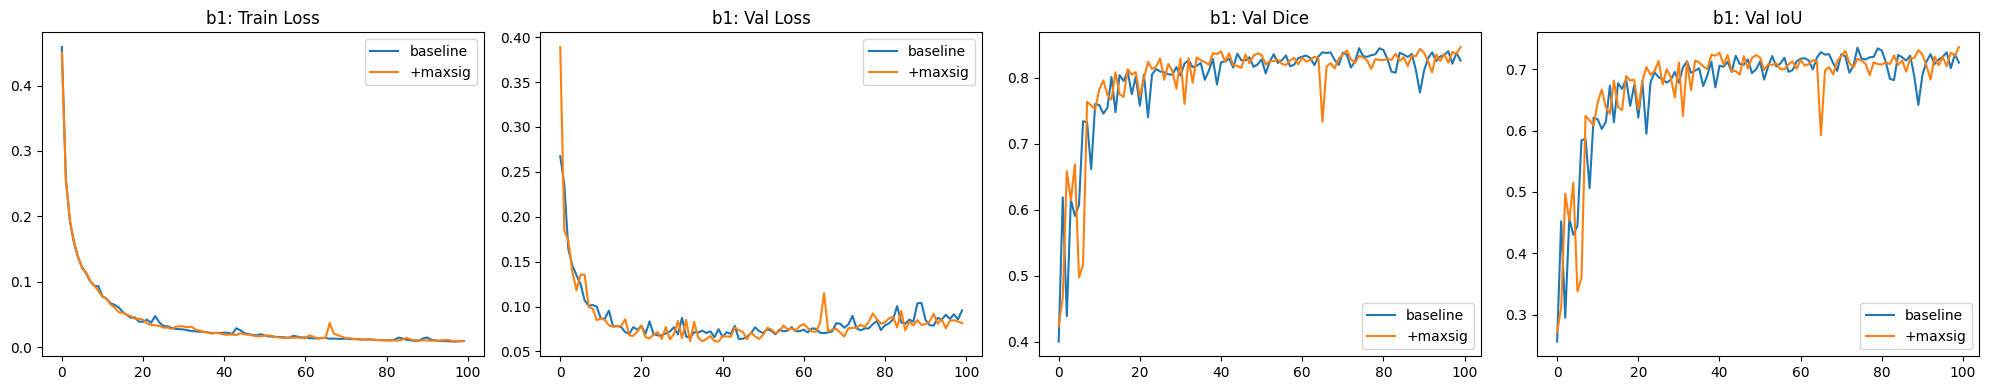

In [15]:
res_b1_baseline = train_and_evaluate(
    "b1", use_maxsig=False, config=config,
    train_dataset=train_dataset, val_dataset=val_dataset, test_dataset=test_dataset,
    device=device,
)

res_b1_maxsig = train_and_evaluate(
    "b1", use_maxsig=True, config=config,
    train_dataset=train_dataset, val_dataset=val_dataset, test_dataset=test_dataset,
    device=device,
)

all_results["b1"] = (res_b1_baseline, res_b1_maxsig)
compare_and_report("b1", res_b1_baseline, res_b1_maxsig)


## SegFormer-B2: baseline vs +MaxSig


segformer_b2_baseline  (maxsig_stages=())
Total parameters: 27,341,121
[segformer_b2_baseline] epoch 1/100  train_loss=0.3447  val_loss=0.1860  val_dice=0.3472  best_dice=0.3472@1  (15.5s)
[segformer_b2_baseline] epoch 2/100  train_loss=0.1543  val_loss=0.1575  val_dice=0.3752  best_dice=0.3752@2  (16.8s)
[segformer_b2_baseline] epoch 3/100  train_loss=0.1243  val_loss=0.1639  val_dice=0.6564  best_dice=0.6564@3  (14.9s)
[segformer_b2_baseline] epoch 4/100  train_loss=0.1106  val_loss=0.1745  val_dice=0.2628  best_dice=0.6564@3  (15.2s)
[segformer_b2_baseline] epoch 5/100  train_loss=0.1061  val_loss=0.1056  val_dice=0.7006  best_dice=0.7006@5  (15.9s)
[segformer_b2_baseline] epoch 6/100  train_loss=0.0946  val_loss=0.0980  val_dice=0.7016  best_dice=0.7016@6  (17.3s)
[segformer_b2_baseline] epoch 7/100  train_loss=0.0888  val_loss=0.0912  val_dice=0.7322  best_dice=0.7322@7  (15.6s)
[segformer_b2_baseline] epoch 8/100  train_loss=0.0844  val_loss=0.0981  val_dice=0.6773  best_dice=0.

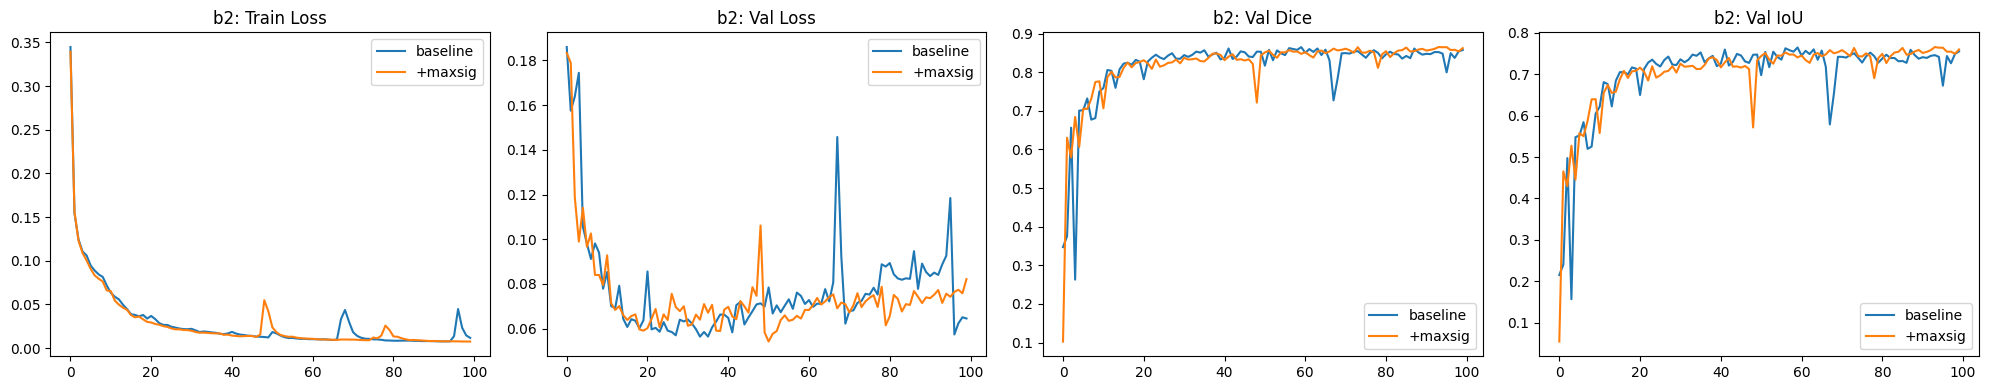

In [16]:
res_b2_baseline = train_and_evaluate(
    "b2", use_maxsig=False, config=config,
    train_dataset=train_dataset, val_dataset=val_dataset, test_dataset=test_dataset,
    device=device,
)

res_b2_maxsig = train_and_evaluate(
    "b2", use_maxsig=True, config=config,
    train_dataset=train_dataset, val_dataset=val_dataset, test_dataset=test_dataset,
    device=device,
)

all_results["b2"] = (res_b2_baseline, res_b2_maxsig)
compare_and_report("b2", res_b2_baseline, res_b2_maxsig)


## SegFormer-B3: baseline vs +MaxSig


segformer_b3_baseline  (maxsig_stages=())
Total parameters: 47,216,961
[segformer_b3_baseline] epoch 1/100  train_loss=0.3314  val_loss=0.2616  val_dice=0.5105  best_dice=0.5105@1  (20.6s)
[segformer_b3_baseline] epoch 2/100  train_loss=0.1589  val_loss=0.2815  val_dice=0.3918  best_dice=0.5105@1  (19.1s)
[segformer_b3_baseline] epoch 3/100  train_loss=0.1277  val_loss=0.1327  val_dice=0.6714  best_dice=0.6714@3  (20.7s)
[segformer_b3_baseline] epoch 4/100  train_loss=0.1106  val_loss=0.1127  val_dice=0.6568  best_dice=0.6714@3  (19.0s)
[segformer_b3_baseline] epoch 5/100  train_loss=0.1008  val_loss=0.1047  val_dice=0.6639  best_dice=0.6714@3  (19.1s)
[segformer_b3_baseline] epoch 6/100  train_loss=0.1000  val_loss=0.1112  val_dice=0.6992  best_dice=0.6992@6  (20.9s)
[segformer_b3_baseline] epoch 7/100  train_loss=0.0908  val_loss=0.1793  val_dice=0.4196  best_dice=0.6992@6  (18.2s)
[segformer_b3_baseline] epoch 8/100  train_loss=0.0854  val_loss=0.1013  val_dice=0.6246  best_dice=0.

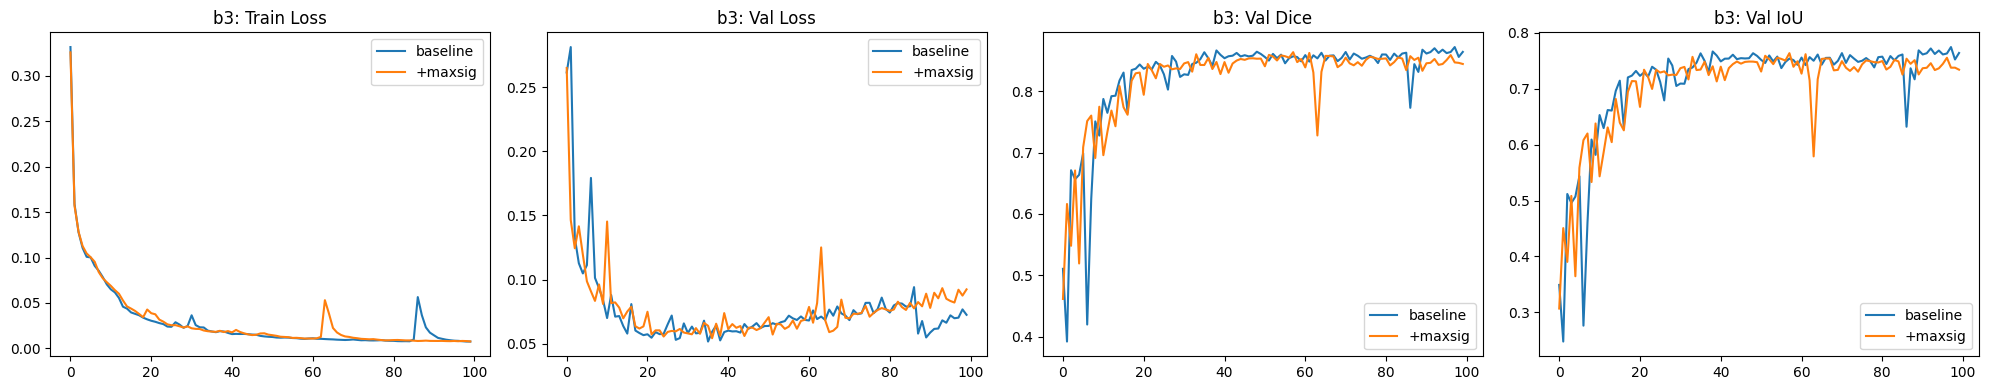

In [17]:
res_b3_baseline = train_and_evaluate(
    "b3", use_maxsig=False, config=config,
    train_dataset=train_dataset, val_dataset=val_dataset, test_dataset=test_dataset,
    device=device,
)

res_b3_maxsig = train_and_evaluate(
    "b3", use_maxsig=True, config=config,
    train_dataset=train_dataset, val_dataset=val_dataset, test_dataset=test_dataset,
    device=device,
)

all_results["b3"] = (res_b3_baseline, res_b3_maxsig)
compare_and_report("b3", res_b3_baseline, res_b3_maxsig)


## SegFormer-B4: baseline vs +MaxSig


segformer_b4_baseline  (maxsig_stages=())
Total parameters: 63,987,521
[segformer_b4_baseline] epoch 1/100  train_loss=0.3116  val_loss=0.2038  val_dice=0.0525  best_dice=0.0525@1  (28.8s)
[segformer_b4_baseline] epoch 2/100  train_loss=0.1609  val_loss=0.1453  val_dice=0.5248  best_dice=0.5248@2  (26.4s)
[segformer_b4_baseline] epoch 3/100  train_loss=0.1248  val_loss=0.1548  val_dice=0.5861  best_dice=0.5861@3  (26.4s)
[segformer_b4_baseline] epoch 4/100  train_loss=0.1132  val_loss=0.1219  val_dice=0.6215  best_dice=0.6215@4  (25.4s)
[segformer_b4_baseline] epoch 5/100  train_loss=0.1016  val_loss=0.1132  val_dice=0.6702  best_dice=0.6702@5  (26.3s)
[segformer_b4_baseline] epoch 6/100  train_loss=0.0939  val_loss=0.1046  val_dice=0.7303  best_dice=0.7303@6  (26.4s)
[segformer_b4_baseline] epoch 7/100  train_loss=0.0887  val_loss=0.0869  val_dice=0.7460  best_dice=0.7460@7  (26.5s)
[segformer_b4_baseline] epoch 8/100  train_loss=0.0805  val_loss=0.0929  val_dice=0.7222  best_dice=0.

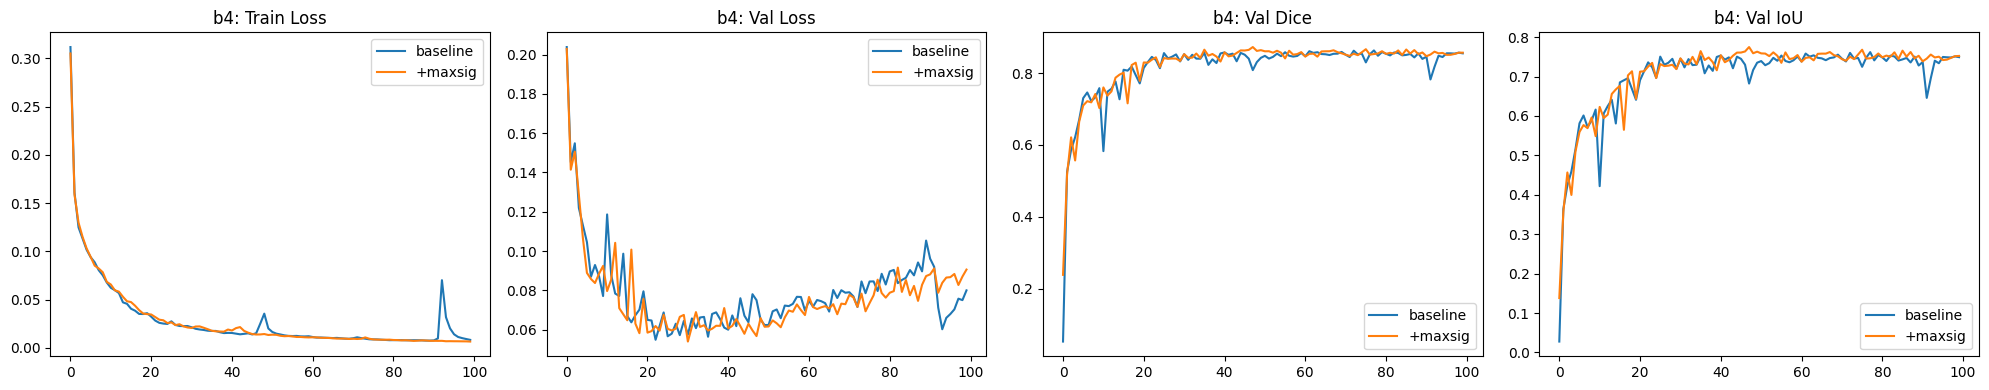

In [18]:
res_b4_baseline = train_and_evaluate(
    "b4", use_maxsig=False, config=config,
    train_dataset=train_dataset, val_dataset=val_dataset, test_dataset=test_dataset,
    device=device,
)

res_b4_maxsig = train_and_evaluate(
    "b4", use_maxsig=True, config=config,
    train_dataset=train_dataset, val_dataset=val_dataset, test_dataset=test_dataset,
    device=device,
)

all_results["b4"] = (res_b4_baseline, res_b4_maxsig)
compare_and_report("b4", res_b4_baseline, res_b4_maxsig)


## SegFormer-B5: baseline vs +MaxSig


segformer_b5_baseline  (maxsig_stages=())
Total parameters: 84,587,841
[segformer_b5_baseline] epoch 1/100  train_loss=0.3400  val_loss=0.1899  val_dice=0.2717  best_dice=0.2717@1  (23.8s)
[segformer_b5_baseline] epoch 2/100  train_loss=0.1638  val_loss=0.1388  val_dice=0.5431  best_dice=0.5431@2  (23.9s)
[segformer_b5_baseline] epoch 3/100  train_loss=0.1312  val_loss=0.1785  val_dice=0.5244  best_dice=0.5431@2  (21.1s)
[segformer_b5_baseline] epoch 4/100  train_loss=0.1310  val_loss=0.1178  val_dice=0.6554  best_dice=0.6554@4  (23.6s)
[segformer_b5_baseline] epoch 5/100  train_loss=0.1109  val_loss=0.1254  val_dice=0.6092  best_dice=0.6554@4  (21.2s)
[segformer_b5_baseline] epoch 6/100  train_loss=0.1096  val_loss=0.1111  val_dice=0.6514  best_dice=0.6554@4  (20.8s)
[segformer_b5_baseline] epoch 7/100  train_loss=0.0996  val_loss=0.1070  val_dice=0.7200  best_dice=0.7200@7  (23.8s)
[segformer_b5_baseline] epoch 8/100  train_loss=0.0980  val_loss=0.1457  val_dice=0.6906  best_dice=0.

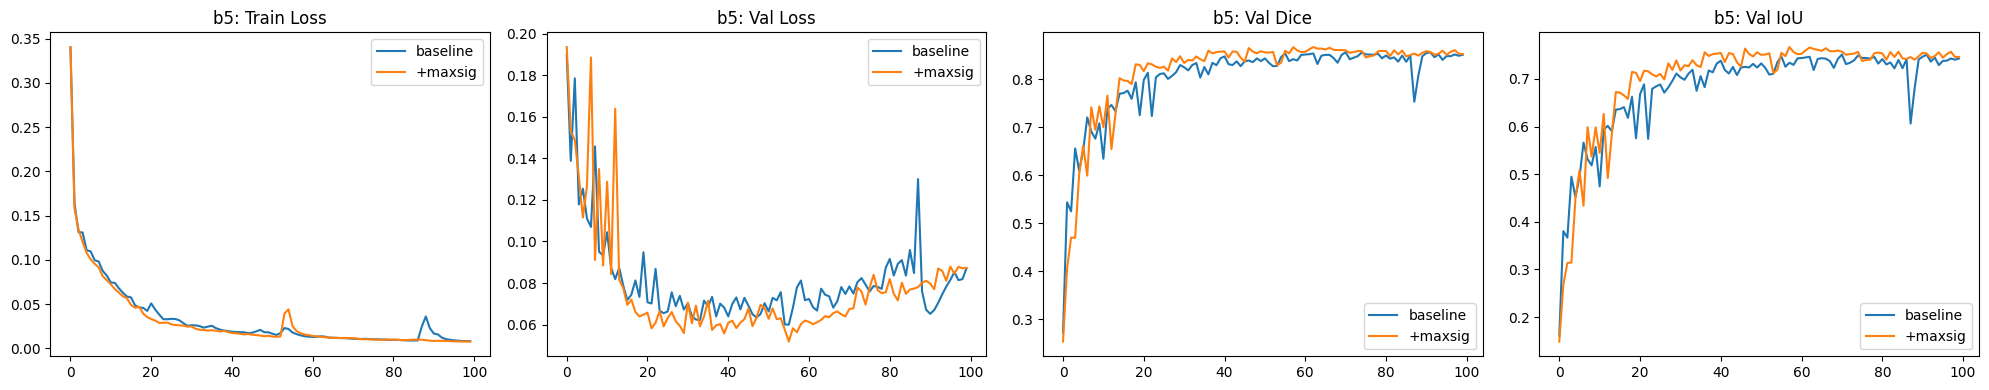

In [19]:
res_b5_baseline = train_and_evaluate(
    "b5", use_maxsig=False, config=config,
    train_dataset=train_dataset, val_dataset=val_dataset, test_dataset=test_dataset,
    device=device,
)

res_b5_maxsig = train_and_evaluate(
    "b5", use_maxsig=True, config=config,
    train_dataset=train_dataset, val_dataset=val_dataset, test_dataset=test_dataset,
    device=device,
)

all_results["b5"] = (res_b5_baseline, res_b5_maxsig)
compare_and_report("b5", res_b5_baseline, res_b5_maxsig)


## Summary across all backbones (B0–B5)

In [20]:
rows = []
for variant, (rb, rm) in all_results.items():
    for res, model_name in ((rb, "baseline"), (rm, "+maxsig")):
        rows.append({
            "variant": variant,
            "model": model_name,
            "params": res["total_params"],
            "gflops": res["gflops"],
            "latency_ms": res["latency_ms_mean"],
            "best_val_dice": res["best_valid_dice"],
            "test_dice": res["test_dice"],
            "test_iou": res["test_iou"],
            "test_hd95_px": res["test_hd95"],
        })

summary_df = pd.DataFrame(rows)
summary_df


,variant,model,params,gflops,latency_ms,best_val_dice,test_dice,test_iou,test_hd95_px
0,b0,baseline,3711265,3.356492,6.781369,0.812743,0.798934,0.670571,24.144425
1,b0,+maxsig,3741451,3.378840,10.439031,0.816995,0.809748,0.683357,21.455026
2,b1,baseline,13671233,6.568280,13.082598,0.844493,0.830226,0.713273,19.000359
3,b1,+maxsig,13790955,6.655967,14.510684,0.846255,0.833312,0.717179,20.246162
4,b2,baseline,27341121,28.299002,23.553403,0.865095,0.753058,0.611734,30.161169
5,b2,+maxsig,27460843,28.386689,30.448820,0.865321,0.843351,0.733429,17.163854
6,b3,baseline,47216961,35.622650,32.698900,0.872440,0.859493,0.757236,15.804791
7,b3,+maxsig,47336683,35.710337,38.834616,0.864112,0.686275,0.533542,33.687788
8,b4,baseline,63987521,42.654958,34.167151,0.863088,0.665519,0.509007,31.344457
9,b4,+maxsig,64107243,42.742645,35.849753,0.872461,0.636163,0.479656,35.715243


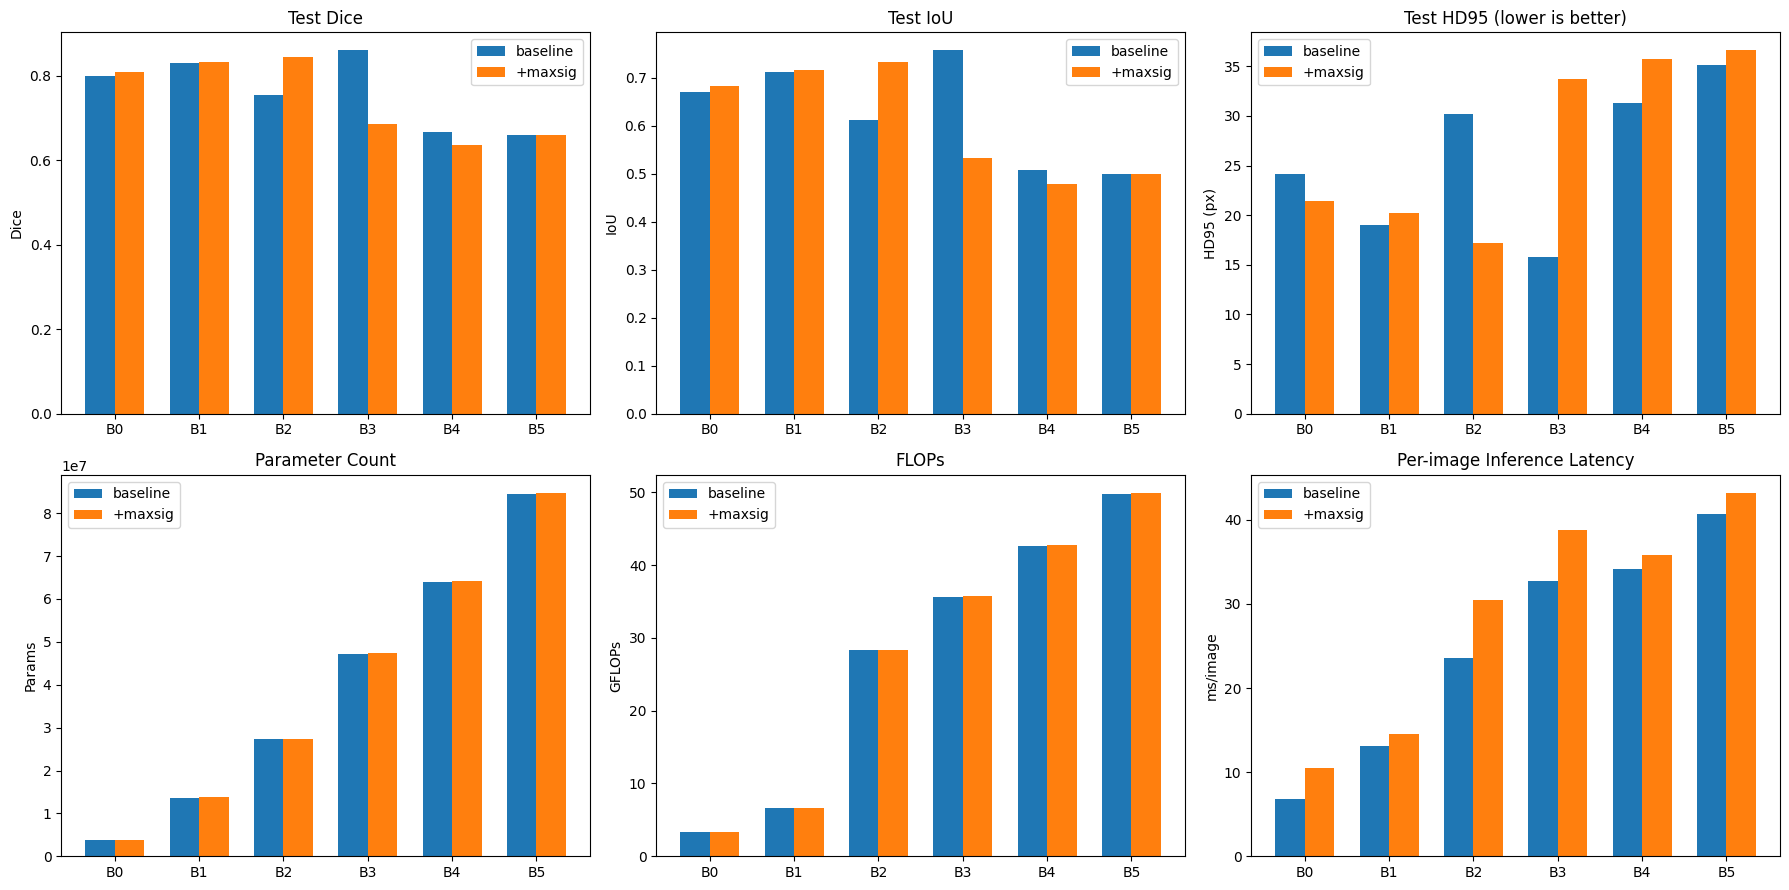

In [21]:
# grouped bar charts: Dice, IoU, HD95, and efficiency (GFLOPs/latency), baseline vs +maxsig,
# across all backbones that have been run so far
variants_run = list(all_results.keys())
x = np.arange(len(variants_run))
width = 0.35

def _pair(metric_key):
    return ([all_results[v][0][metric_key] for v in variants_run],
             [all_results[v][1][metric_key] for v in variants_run])

fig, axes = plt.subplots(2, 3, figsize=(18, 9))

for ax, key, title, ylabel in [
    (axes[0, 0], "test_dice", "Test Dice", "Dice"),
    (axes[0, 1], "test_iou", "Test IoU", "IoU"),
    (axes[0, 2], "test_hd95", "Test HD95 (lower is better)", "HD95 (px)"),
    (axes[1, 0], "total_params", "Parameter Count", "Params"),
    (axes[1, 1], "gflops", "FLOPs", "GFLOPs"),
    (axes[1, 2], "latency_ms_mean", "Per-image Inference Latency", "ms/image"),
]:
    baseline_vals, maxsig_vals = _pair(key)
    ax.bar(x - width/2, baseline_vals, width, label="baseline")
    ax.bar(x + width/2, maxsig_vals, width, label="+maxsig")
    ax.set_xticks(x)
    ax.set_xticklabels([v.upper() for v in variants_run])
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.show()
